# overfitting stress tests analysis
Andrew E. Davidson   
aedavids@ucsc.edu  
Date: 2026-01-27.  
Copyright (c) 2020-2027, Regents of the University of California All rights reserved.  
https://polyformproject.org/licenses/noncommercial/1.0.0  

Figure 3. Stress-test workflow for evaluating model performance as feature dimensionality increases.

see 
- graceM/src/python/overfittingStressTestRunner.py
- graceM/src/bin/overfittingStressTestRunner/*.sh


In [1]:
defaultNotebookName="overfittingStressTestAnalysis"

from cliUtilities import configLogging
import logging

# rootLogger = configLogging(logLevel="INFO")
rootLogger = configLogging(logLevel="WARN")
logger = logging.getLogger(__name__)

2026-10-16 11:58:24,755 WARNING cliUtilities.py configLogging() line:61] [BEGIN]
2026-10-16 11:58:24,756 WARNING cliUtilities.py configLogging() line:67] [PYTHONPATH : /private/home/aedavids/fagazi/src/python:/private/home/aedavids/fagazi/src/jupyterNotebooks]
2026-10-16 11:58:24,756 WARNING cliUtilities.py configLogging() line:68] [FILE: /private/home/aedavids/fagazi/src/python/cliUtilities.py]
2026-10-16 11:58:24,757 WARNING cliUtilities.py configLogging() line:69] [PWD: /private/home/aedavids/fagazi/src/jupyterNotebooks/flagship]


In [2]:
# from IPython.display import display
# import json
import matplotlib.pyplot as plt
from matplotlib.figure import Figure
# set up matplotlib default final artwork complient styles
from plots.plotPanel import natureManuscriptStyle
plt.rcParams.update(natureManuscriptStyle)

import os
import pandas as pd
# from pprint import pprint

import time
from typing import  Dict, List, Tuple

# local imports
from notebookUtils import appendToPYTHONPATH, getNotebookName

ORIG_PYTHONPATH = os.environ['PYTHONPATH']

# extraRNA_PythonPath1 = '/private/home/aedavids/extraCellularRNA' 
# extraRNA_PythonPath2 = '/private/home/aedavids/extraCellularRNA/src'
# appendToPYTHONPATH([extraRNA_PythonPath1, extraRNA_PythonPath2]) 

from plots.plotPanel import combineFigures, displayPDFInNotebook, removeLegends
from plots.plotUtilities import saveFigure

notebook_start_time = time.time()
print("⏱️ Notebook started.")

⏱️ Notebook started.


In [3]:
notebookName, notebookDir = getNotebookName(defaultNotebookName)
print(f'notebookName: {notebookName}')
print(f'notebookDir: {notebookDir}')
notebookOutDir = f'{notebookDir}/{notebookName}.out'
print(f'notebookOutDir: {notebookOutDir}')
os.makedirs(notebookOutDir, exist_ok=True)

imgOut = f'{notebookOutDir}/img.out'
os.makedirs(imgOut, exist_ok=True)

# diagnosis: Colorectal  Esophagus  Liver  Lung  Stomach
#diagnosis_G = "Colorectal"
# diagnosis_G = "Esophagus"
# diagnosis_G = "Liver"
# diagnosis_G = "Lung"
# diagnosis_G = "Stomach"

diagnosisLst_G = ["Colorectal",  "Esophagus", "Liver", "Lung", "Stomach"]
localCachePath_G = f"/scratch/aedavids/fagazi/simulatedData/overfittingStressTestRunner"

notebookName: overfittingStressTestAnalysis
notebookDir: /private/home/aedavids/fagazi/src/jupyterNotebooks/flagship
notebookOutDir: /private/home/aedavids/fagazi/src/jupyterNotebooks/flagship/overfittingStressTestAnalysis.out


# Load and clean repeat data sets

In [4]:
# overfittingStressTestRunner/ is the bin/*Runner.sh output dir
# localCachePath_G = f"/scratch/aedavids/fagazi/simulatedData/overfittingStressTestRunner"
# ColorectalRepeatsPath = f'{localCachePath_G}/Colorectal_Cancer/repeats_lfc2.0_padj0.05_specficity0.9.csv'
# EsophagusRepeatsPath = f'{localCachePath_G}/Esophagus_Cancer/repeats_lfc2.0_padj0.05_specficity0.9.csv'
# diagnosisRepeatsPath = f'{localCachePath_G}/{diagnosis_G}_Cancer/repeats_lfc2.0_padj0.05_specficity0.9.csv'

# TestDirPath = f'/private/home/aedavids/fagazi/src/jupyterNotebooks/flagship/overfittingStressTest.out'
# tesEsophagusPath = f"{TestDirPath}/Esophagus_Cancer/repeats.csv"
# tesDiagnosisRepeatsPath = f"{TestDirPath}/{diagnosis_G}_Cancer/repeats.csv"

In [5]:
diagnosisRepeatsPathDict = { d : f'{localCachePath_G}/{d}_Cancer/repeats_lfc2.0_padj0.05_specficity0.9.csv' for d in diagnosisLst_G}
diagnosisRepeatsPathDict

{'Colorectal': '/scratch/aedavids/fagazi/simulatedData/overfittingStressTestRunner/Colorectal_Cancer/repeats_lfc2.0_padj0.05_specficity0.9.csv',
 'Esophagus': '/scratch/aedavids/fagazi/simulatedData/overfittingStressTestRunner/Esophagus_Cancer/repeats_lfc2.0_padj0.05_specficity0.9.csv',
 'Liver': '/scratch/aedavids/fagazi/simulatedData/overfittingStressTestRunner/Liver_Cancer/repeats_lfc2.0_padj0.05_specficity0.9.csv',
 'Lung': '/scratch/aedavids/fagazi/simulatedData/overfittingStressTestRunner/Lung_Cancer/repeats_lfc2.0_padj0.05_specficity0.9.csv',
 'Stomach': '/scratch/aedavids/fagazi/simulatedData/overfittingStressTestRunner/Stomach_Cancer/repeats_lfc2.0_padj0.05_specficity0.9.csv'}

In [6]:
# # rawDF = pd.read_csv(ColorectalRepeatsPath)
# rawDF_G = pd.read_csv(diagnosisRepeatsPath)
# # rawDF = pd.read_csv(tesEsophagusPath)

In [7]:
# print(rawDF_G.shape)
# # print(rawDF.columns)
# rawDF_G.iloc[0:5, 0:5]


In [8]:
def cleanUp(rawDF : pd.DataFrame 
            ) -> pd.DataFrame:
    '''
    drop dupicate cols. ie _diagnosis, _numFeatures, _repeatId, _repeatSeed _nFolds
    
    renames columns to make it easier to debug.
    e.g. auc and acc are easy to mix up
    '''
    # drop expected duplicate columns
    simDups = ['SimTrain_diagnosis', 'SimTrain_numFeatures', 'SimTrain_repeatId',
            'SimTrain_repeatSeed', 'SimTrain_nFolds']
    notSimDups = [ s for s in rawDF.columns if not s in simDups]
    raw1DF = rawDF.loc[ :, notSimDups]
    # print("\n******raw1DF")
    # print(raw1DF.shape)
    # print( raw1DF.columns)


    realTestDups = ['realTest_diagnosis', 'realTest_numFeatures', 
                    'realTest_repeatId', 'realTest_repeatSeed','realTest_nFolds']

    notRealTestDups = [ r for r in raw1DF.columns if not r in realTestDups]
    raw2DF = raw1DF.loc[:, notRealTestDups]
    # print("\n******raw2DF")
    # print(raw2DF.shape)
    # print( raw2DF.columns)

    raw3DF = raw2DF.rename(columns={
                    'realFit_diagnosis'   :"diagnosis",
                    'realFit_numFeatures' :"numFeatures",
                    'realFit_repeatId'    : "repeatId",
                    'realFit_repeatSeed'  :"repeatSeed",
                    'realFit_nFolds'      : "nFolds",
                    
                    # it is to easy to mix up auc and acc
                    'realFit_accMean' : 'realFit_accuracyMean',
                    'realFit_accStd'  : 'realFit_accuracyStd',
                
                    'SimTrain_accMean' : 'SimTrain_accuracyMean',
                    'SimTrain_accStd'  : 'SimTrain_accuracyStd',

                    'realTest_accMean' : 'realTest_accuracyMean',
                    'realTest_accStd'  : 'realTest_accuracyStd',                               
                    })

    # print("\n******raw3DF rename common cols")
    # print(raw3DF.shape)
    # print( raw3DF.columns)
    
    return raw3DF

In [9]:
# repeatsDF_G = cleanUp(rawDF_G)
# print(repeatsDF_G.shape)
# print(repeatsDF_G.columns)
# repeatsDF_G.head()

In [10]:
# sanity check
def findDuplicateValueColumnSources(df: pd.DataFrame, 
                                    targetCols: List[str]
                                    ) -> Dict[str, List[str]]:
    '''
    we expect the metrics for realFit, simTrain, realTest to be
    slightly different.
    
    duplicateColSeries = rawDF.T.duplicated()
    duplicateColSeries[ duplicateColSeries == True ]
    
    finds lots of dups we expecte for example
        *_diagnosis, *_numFeatures, *_repeatId  
        
    it also reports some of the metrics are dupes. for example
        SimTrain_sensitivityAtMean.
        
    sensitivityAtMean is not a duplicate of realFit__sensitivityAtMean, 
    or realTest_sensitivityAtMean. 
    
    it must match some other columns value 
    '''
    duplicateSources: Dict[str, List[str]] = {}
    colNames = list(df.columns)

    for col in targetCols:
        colIdx = colNames.index(col)
        earlierCols = colNames[:colIdx]  # only columns before this one (duplicated() behavior)

        matches: List[str] = []
        for other in earlierCols:
            # skip self (not needed since earlierCols excludes it, but safe)
            if other == col:
                # print(f"aedwip {other} == {col}")
                continue  

            # compare full column values
            if df[col].equals(df[other]) : # : and not other in matches :
                # print(f"other : {other} matches : {matches}")
                matches.append(other)

        if len(matches) > 0: 
            duplicateSources[col] = matches

    return duplicateSources
 

suspectCols = [
    'realFit_nFiniteThreshold',
    "SimTrain_aucMean",
    "SimTrain_aucStd",
    "SimTrain_sensitivityAtMean",
    "SimTrain_sensitivityAtStd",
]

# duplicateColSeries = repeatsDF_G.T.duplicated()
# duplicateColSeries[ duplicateColSeries == True ]
# suspectCols =  duplicateColSeries[duplicateColSeries].index
# dupSources = findDuplicateValueColumnSources(repeatsDF_G, suspectCols)
# for col, sources in dupSources.items():
#     print(col, "matches:", sources)

In [11]:
def createPlotDF(
            repeatDF : pd.DataFrame,
            statSuffix : list[str] = [
                                        # '_accuracyMean', '_accuracyStd', '_aucMean','_aucStd', 
                                        '_sensitivityAtMean',
                                        # '_sensitivityAtStd', '_thresholdMean','t_thresholdStd', 
                                    ],

    ) -> tuple[pd.DataFrame, list[str]] :
    ''' 
    create plotable repeat data by calculating the mean of rows 
    grouped by 'diagnosis' and 'numFeatures'
    
    arguments:
        repeatDF:
            created from one or more repeats_lfc2.0_padj0.05_specficity0.9.csv files
            make sure you have called cleanUp()
            
        statSuffix :
            list of stats you want to plot
            
            examples: 
                ['_accuracyMean', '_accuracyStd', '_aucMean','_aucStd',
                '_sensitivityAtMean', '_sensitivityAtStd',
                '_thresholdMean','t_thresholdStd',]
            
    returns 
        a dataFrame and list of the stat columns
        example:
            returned data frame columns
                [numFeatures, realFit_sensitivityAtMean, 
                SimTrain_sensitivityAtMean, realTest_sensitivityAtMean]
                
            stats columns
                ['realFit_sensitivityAtMean', 
                'SimTrain_sensitivityAtMean',
                'realTest_sensitivityAtMean']
    '''
    statPrefix = ['realFit', 'SimTrain', 'realTest']

    statCols = [ pre + suf for pre in statPrefix  for suf in statSuffix]

    accumulatorDict = dict()
    for keys, groupDF in repeatDF.groupby(['diagnosis', 'numFeatures']):
        featureMeansSeries = groupDF[statCols].mean()
        
        # example keys: for groupby(['diagnosis', 'numFeatures'])
        # ('Colorectal', 5)
        diag,numFeature = keys
        print(f'groupby({diag} {numFeature})')
        accumulatorDict[numFeature] = featureMeansSeries
        

    accumulatorDF = pd.DataFrame(accumulatorDict)
    retDF = accumulatorDF.transpose().reset_index(names="numFeatures")
    
    return (retDF, statCols)


# aedwipDF, aedwpStatsCols= createPlotDF(repeatsDF_G)
# # aedwipDF
# aedwpStatsCols

In [12]:
def loadRepeatDataSets(
        pathDict : dict[str, str],
        statSuffix : list[str] = [
                                            # '_accuracyMean', '_accuracyStd', '_aucMean','_aucStd', 
                                            '_sensitivityAtMean',
                                            # '_sensitivityAtStd', '_thresholdMean','t_thresholdStd', 
                                        ],
    ) -> dict[str, pd.DataFrame]:
    ''' 
    
    arguments:
    
        statSuffix :
            list of stats you want to plot
            
            examples: 
                ['_accuracyMean', '_accuracyStd', '_aucMean','_aucStd',
                '_sensitivityAtMean', '_sensitivityAtStd',
                '_thresholdMean','t_thresholdStd',]
                
                
    returns
        dictionary of data frames
            key = diagnosis
                
    '''
    retDict = dict()
    
    suspectCols = [
        'realFit_nFiniteThreshold',
        "SimTrain_aucMean",
        "SimTrain_aucStd",
        "SimTrain_sensitivityAtMean",
        "SimTrain_sensitivityAtStd",
    ]
    for diagnosis, path in pathDict.items():
        print(f'\n*****{diagnosis} {path}')
        rawDF = pd.read_csv(path, )
        print(f'raw.shape : {rawDF.shape} ')
        
        cleanDF = cleanUp(rawDF)
        print(f'cleanDF.shape : {cleanDF.shape} ')

        dupSources = findDuplicateValueColumnSources(cleanDF, suspectCols)
        print(f'check for duplicate metric cols. ie bug in stess test')
        for col, sources in dupSources.items():
            print(col, "matches:", sources)
            
        plotDF, statCols = createPlotDF(cleanDF, statSuffix)
        print(f'plotDF.shape : {plotDF.shape} ')

        retDict[diagnosis] = plotDF
        
        
    return retDict
        
        
        
sensitivityAtMeanDict_G = loadRepeatDataSets(diagnosisRepeatsPathDict, statSuffix=['_sensitivityAtMean'])


*****Colorectal /scratch/aedavids/fagazi/simulatedData/overfittingStressTestRunner/Colorectal_Cancer/repeats_lfc2.0_padj0.05_specficity0.9.csv
raw.shape : (350, 42) 
cleanDF.shape : (350, 32) 
check for duplicate metric cols. ie bug in stess test
SimTrain_aucMean matches: ['SimTrain_accuracyMean']
SimTrain_sensitivityAtMean matches: ['SimTrain_accuracyMean', 'SimTrain_aucMean']
SimTrain_sensitivityAtStd matches: ['SimTrain_accuracyStd']
groupby(Colorectal 5)
groupby(Colorectal 10)
groupby(Colorectal 25)
groupby(Colorectal 50)
groupby(Colorectal 100)
groupby(Colorectal 200)
groupby(Colorectal 400)
plotDF.shape : (7, 4) 

*****Esophagus /scratch/aedavids/fagazi/simulatedData/overfittingStressTestRunner/Esophagus_Cancer/repeats_lfc2.0_padj0.05_specficity0.9.csv
raw.shape : (300, 42) 
cleanDF.shape : (300, 32) 
check for duplicate metric cols. ie bug in stess test
SimTrain_aucMean matches: ['SimTrain_accuracyMean']
SimTrain_sensitivityAtMean matches: ['SimTrain_accuracyMean', 'SimTrain_au

# Plots

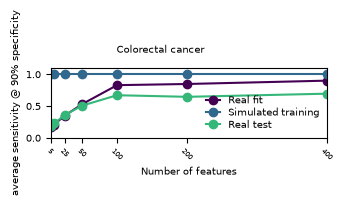

In [13]:
def plotRepeats(
        diagnosis : str,
        repeatsDF : pd.DataFrame,
        dataSetCols : list[str],
        yLabel : str,
        panelWidthInMM : int = 180,
        panelHeightInMM : int = 185,
        nPanelColumns : int = 1,
        nPanelRows : int = 1,
        fontSize : int = 7, 
    ) -> Figure :
    '''     
    assumptions: 
        - repeatsDF is single diagnosis
        - returned plots will be combined into a final panel
        with panelWidthInMM and panelHeightInMM
        
    arguments:
    
        yLabel
            example : 'average sensitivity @ 90% specificity'
    
        dataSetCols:
            example : ['realFit_sensitivityAtMean', 
                'SimTrain_sensitivityAtMean',
                'realTest_sensitivityAtMean']
                
        panelWidthInMM : 
            default = 180 mm, nature's max width for 2 columns of text paper
         
        panelHeightInMM :
            default = 185 mm, nature's length of figure caption < 300 words (max)
            
        nPanelColumns :
            default = 1
            used to automatically size plot for use in a panel
            
        nPanelRows :
            default = 1
            used to automatically size plot for use in a panel

 
        fontSize :
            default 7pt is nature bio medical engineerings 
            max size. min is 5pt
            
            
    ref : https://www.nature.com/documents/NRJs-guide-to-preparing-final-artwork.pdf

    '''
    # set up figure
    # standard paper size is 8.5 inches x 11 inches
    # pageWidthInInches = 4 + 4 #5
    pageWidthInInches = (panelWidthInMM / nPanelColumns) / 25.4
    # pageHeightInInches = 3
    pageHeightInInches = (panelHeightInMM / nPanelRows) / 25.4
    fig = plt.figure( figsize=( pageWidthInInches, pageHeightInInches ) )
    panel = fig.gca() # get current axes
    
    fig.suptitle(diagnosis + " cancer", fontsize=fontSize)
    # panel.set_title(diagnosis)
    
    xMin = repeatsDF['numFeatures'].min()
    xMax = repeatsDF['numFeatures'].max()
    panel.set_xlim( xMin, xMax )
    
    # for plots with x-axis range [0,400]x tick values 5 and 10 overlap
    # do not display 10
    allXVals = repeatsDF['numFeatures'].tolist()
    xVals = [v for v in sorted(set(allXVals)) if v != 10]

    panel.set_xticks(xVals)
    panel.set_xticklabels([str(v) for v in xVals], fontsize=5, rotation=-45)
    # panel.set_xticklabels([str(v) for v in xVals], fontsize=6, rotation=-50)
    #panel.set_xticklabels([str(v) for v in xVals], fontsize=6, rotation=-90)

    yMin = 0.0
    # sensitivity and accuacy are [0,1.0]. May the y axis a little longer
    yMax = 1 + 0.1
    panel.set_ylim( yMin, yMax )
    
    panel.set_xlabel( 'Number of features')
    #panel.set_ylabel( 'average sensitivity @ 90% specificity' )
    panel.set_ylabel( yLabel )
    
    for i, dataSet in enumerate(dataSetCols):
        df = repeatsDF.loc[:, ['numFeatures', dataSet]]
        # print(f'aedwip {dataSet} df.shape : {df.shape}')
        # print(df)
        color = plt.cm.viridis(i / len(dataSetCols))   # pick a color from the colormap
        panel.plot( df['numFeatures'], df[dataSet],
                   label=dataSet, 
                   color=color,
                   marker='o', # circle
                   )
        
    # add the legend
    # panel.legend()
  
    # Preserve the plotted dataset names; shorten only the displayed labels.
    legendLabels = ["Real fit", "Simulated training", "Real test"]

    handles, _ = panel.get_legend_handles_labels()
    panel.legend(
        handles,
        legendLabels,  # Must match the order of dataSetCols.
        loc="lower right",
        fontsize=fontSize,
        frameon=False,
        handlelength=1.5,
        labelspacing=0.2,
        borderaxespad=0.4,
    )  
    
    # set the fonts
    # panel.tick_params(axis='both', labelsize=fontSize)
    # 5pt is min final artwork. for plots with big x range, 5 and 10 
    # ticks overlap
    panel.tick_params(axis='x', labelsize=5)
    panel.tick_params(axis='y', labelsize=fontSize)
    panel.xaxis.label.set_size(fontSize)
    panel.yaxis.label.set_size(fontSize)
    panel.title.set_fontsize(fontSize)

    legend = panel.get_legend()
    if legend is not None:
        for text in legend.get_texts():
            text.set_fontsize(fontSize) 
        legend.get_title().set_fontsize(fontSize)   
    
     # Reserve space inside the fixed-size canvas for labels and title.
    fig.subplots_adjust(
        left=0.19, # moves the plot away from left edge
        right=0.97,
        bottom=0.34, # raise the plot to make room for x-axis label
        top=0.82,
    )

    return fig

    
def testPlotRepeats() :   
    # plotDF, statCols = createPlotDF(repeatsDF_G,
    #                                 statSuffix=['_sensitivityAtMean',] 
    #                                 )
    
    d = 'Colorectal'
    df = sensitivityAtMeanDict_G[d]
    statCols = [c for c in df.columns if c != 'numFeatures']
    fig = plotRepeats(
            diagnosis=d,
            repeatsDF=df,
            dataSetCols=statCols,
            yLabel='average sensitivity @ 90% specificity',
            nPanelColumns=2,
            nPanelRows=5,
            )
    
    
    
testPlotRepeats()


## <span style="color:red;background-color:yellow;">10/4/26 F-r2-2</span>
combineFigure panel size parameters

In [14]:
F_r2_2_panelWidthInMM = 180
F_r2_2_legendHeightMm = 18
F_r2_2_panelHeightInMM = 185 - F_r2_2_legendHeightMm # data grid only
F_r2_2_nPanelRows = 5
F_r2_2_nPanelColumns = 2

## plot sensitivityAtMean for all cancer type

2026-10-16 11:58:27,592 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/flagship/overfittingStressTestAnalysis.out/img.out/averageSensitivityAt90PercentSpecificity/_Colorectal-cancer.png]
2026-10-16 11:58:27,951 WARNING archiveUtilities.py saveFigure() line:203] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/flagship/overfittingStressTestAnalysis.out/img.out/averageSensitivityAt90PercentSpecificity/_Colorectal-cancer.pdf]
2026-10-16 11:58:28,129 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/flagship/overfittingStressTestAnalysis.out/img.out/averageSensitivityAt90PercentSpecificity/_Esophagus-cancer.png]
2026-10-16 11:58:28,444 WARNING archiveUtilities.py saveFigure() line:203] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/flagship/overfittingStressTestAnalysis.out/img.out/averageSensitivityAt90PercentSpecificity/_Esophagus-cancer.pdf

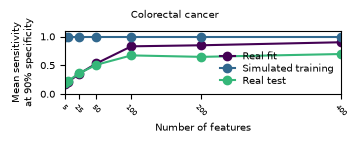

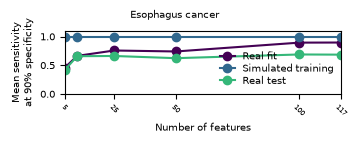

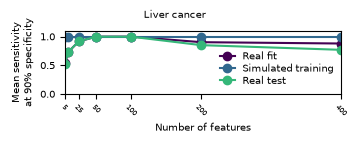

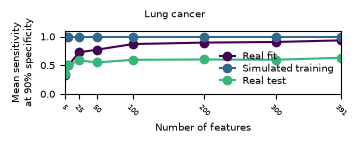

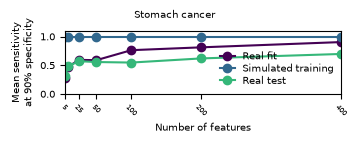

In [15]:
def plotAverageSensitityAt(
            panelWidthInMM : int = 180,
            panelHeightInMM : int = 185,
            nPanelColumns : int = 1,
            nPanelRows : int = 1,
    ) -> list[plt.figure]:
    ''' 
    TODO
    '''
    retFigList = []
    for diagnosis,plotDF in sensitivityAtMeanDict_G.items():
        statCols = [c for c in plotDF.columns if c != 'numFeatures']
        fig = plotRepeats(
                diagnosis=diagnosis,
                repeatsDF=plotDF,
                dataSetCols=statCols,
                # yLabel='average sensitivity @ 90% specificity',
                # yLabel="mean sensitivity\nat 90% specificity",
                # yLabel="sensitivity at 90% spec.",
                # yLabel="mean sens. at 90% spec.",
                # yLabel="mean sens. 90% spec.",
                # yLabel="Mean sensitivity at 90% specificity",
                yLabel = "Mean sensitivity\nat 90% specificity",
                panelWidthInMM=panelWidthInMM,
                panelHeightInMM=panelHeightInMM,
                nPanelColumns=nPanelColumns, #2,
                nPanelRows=nPanelRows, #5,
                )
        retFigList.append(fig)
        
        outDirArg = f'{imgOut}/averageSensitivityAt90PercentSpecificity'
        suptitle = fig._suptitle.get_text() 
        saveFigure(fig, suptitle, outDirArg)
        
    return retFigList
        
averageSensitivityAtFigList = plotAverageSensitityAt(
                                    panelWidthInMM=F_r2_2_panelWidthInMM,
                                    panelHeightInMM=F_r2_2_panelHeightInMM,
                                    nPanelRows=F_r2_2_nPanelRows,
                                    nPanelColumns=F_r2_2_nPanelColumns,
                                )  

## plot average accuracy


*****Colorectal /scratch/aedavids/fagazi/simulatedData/overfittingStressTestRunner/Colorectal_Cancer/repeats_lfc2.0_padj0.05_specficity0.9.csv
raw.shape : (350, 42) 
cleanDF.shape : (350, 32) 
check for duplicate metric cols. ie bug in stess test
SimTrain_aucMean matches: ['SimTrain_accuracyMean']
SimTrain_sensitivityAtMean matches: ['SimTrain_accuracyMean', 'SimTrain_aucMean']
SimTrain_sensitivityAtStd matches: ['SimTrain_accuracyStd']
groupby(Colorectal 5)
groupby(Colorectal 10)
groupby(Colorectal 25)
groupby(Colorectal 50)
groupby(Colorectal 100)
groupby(Colorectal 200)
groupby(Colorectal 400)
plotDF.shape : (7, 4) 

*****Esophagus /scratch/aedavids/fagazi/simulatedData/overfittingStressTestRunner/Esophagus_Cancer/repeats_lfc2.0_padj0.05_specficity0.9.csv
raw.shape : (300, 42) 
cleanDF.shape : (300, 32) 
check for duplicate metric cols. ie bug in stess test
SimTrain_aucMean matches: ['SimTrain_accuracyMean']
SimTrain_sensitivityAtMean matches: ['SimTrain_accuracyMean', 'SimTrain_au

2026-10-16 11:58:30,484 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/flagship/overfittingStressTestAnalysis.out/img.out/averageAccuracy/_Colorectal-cancer.png]
2026-10-16 11:58:30,686 WARNING archiveUtilities.py saveFigure() line:203] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/flagship/overfittingStressTestAnalysis.out/img.out/averageAccuracy/_Colorectal-cancer.pdf]
2026-10-16 11:58:30,847 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/flagship/overfittingStressTestAnalysis.out/img.out/averageAccuracy/_Esophagus-cancer.png]
2026-10-16 11:58:31,190 WARNING archiveUtilities.py saveFigure() line:203] [saved : /private/home/aedavids/fagazi/src/jupyterNotebooks/flagship/overfittingStressTestAnalysis.out/img.out/averageAccuracy/_Esophagus-cancer.pdf]
2026-10-16 11:58:31,355 WARNING archiveUtilities.py saveFigure() line:200] [saved : /private/home/

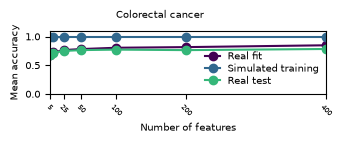

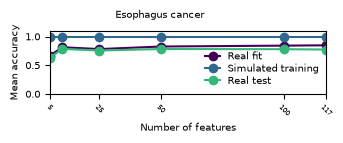

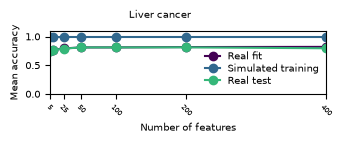

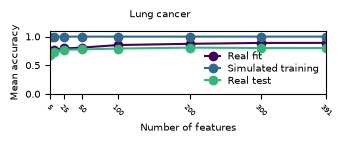

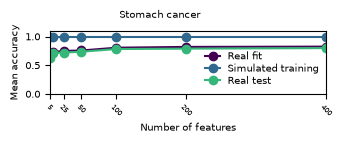

In [16]:
def plotAverageAccuracy(
                panelWidthInMM : int = 180,
                panelHeightInMM : int = 185,
                nPanelColumns : int = 1,
                nPanelRows : int = 1,
    ) -> list[plt.figure] :
    ''' 
    TODO 
    '''
    retFigList = []
    accuracyMeanDict_G = loadRepeatDataSets(diagnosisRepeatsPathDict, statSuffix=['_accuracyMean'])
    for diagnosis,plotDF in accuracyMeanDict_G.items():
        statCols = [c for c in plotDF.columns if c != 'numFeatures']
        fig = plotRepeats(
                diagnosis=diagnosis,
                repeatsDF=plotDF,
                dataSetCols=statCols,
                # yLabel='average accuracy',
                yLabel='Mean accuracy',                
                panelWidthInMM=panelWidthInMM,
                panelHeightInMM=panelHeightInMM,
                nPanelColumns=nPanelColumns, #=2,
                nPanelRows=nPanelRows, #5,
                )
        retFigList.append(fig)
        
        outDirArg = f'{imgOut}/averageAccuracy'
        suptitle = fig._suptitle.get_text() 
        saveFigure(fig, suptitle, outDirArg)    
        
    return retFigList
        
t = plotAverageAccuracy(
        panelWidthInMM=F_r2_2_panelWidthInMM,
        panelHeightInMM=F_r2_2_panelHeightInMM,
        nPanelRows=F_r2_2_nPanelRows,
        nPanelColumns=F_r2_2_nPanelColumns,
    )   
averageAccuracyAtFigList = t

In [17]:
# sensitivityAt90SpecificityOutputStem = f'{imgOut}/manuscript/sensitivityAt90SpecificityPanel'
# t = combineFigures(
#                 averageSensitivityAtFigList,
#                 sensitivityAt90SpecificityOutputStem,
#                 bottomMargin=0.18 #0.15 #0.10 #0.20 #0.20
#                 )

# sensitivityAt90SpecificityOutputStemManuscriptPdfPath, pngPath = t
# displayPDFInNotebook(sensitivityAt90SpecificityOutputStemManuscriptPdfPath)

# <span style="color:red;background-color:yellow;">10/3/26 create final artwork</span>

panel width = 180 mm == 7.09 inches
panel height = 185 mm == 7.28 inches

figsize = (180/25.4, 185/25.4)

In [18]:

# averageAccuracyOutputStem = f'{imgOut}/manuscript/averageAccuracyPanel'
# t = combineFigures(
#                 averageAccuracyAtFigList,
#                 averageAccuracyOutputStem,
#                 bottomMargin=0.20 #0.20
#                 )

# averageAccuracyStemManuscriptPdfPath, pngPath = t
# displayPDFInNotebook(averageAccuracyStemManuscriptPdfPath)

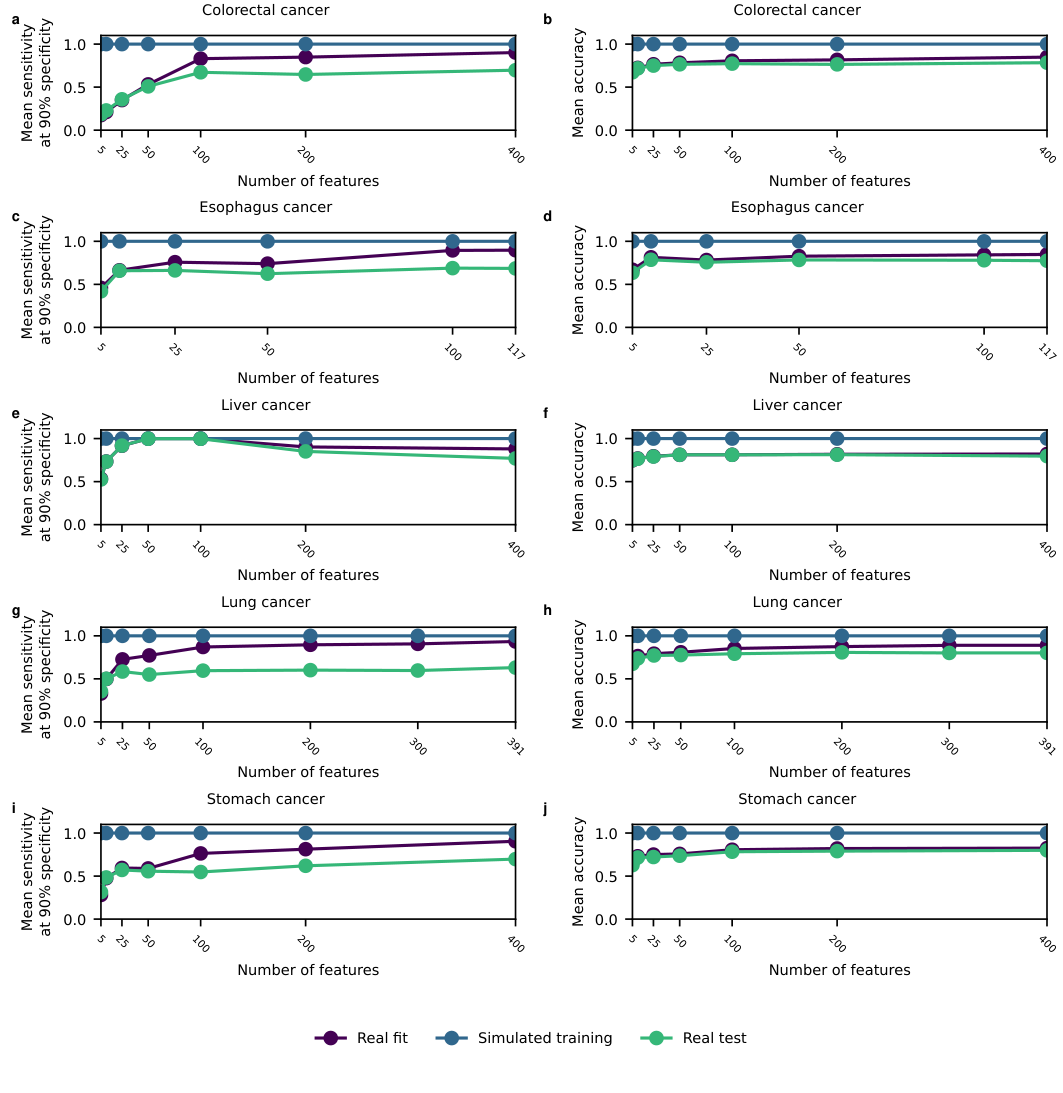

save : /private/home/aedavids/fagazi/src/jupyterNotebooks/flagship/overfittingStressTestAnalysis.out/img.out/manuscript/F-r2-2PerformancePanel.pdf


<Figure size 708.661x70.8661 with 0 Axes>

In [19]:

colIdx = 0
escopIdx = 1
liverIdx = 2
lungIdx = 3
StomachIdx = 4

# order the subplot figures
originalTestFigs = [
    averageSensitivityAtFigList[colIdx],     averageAccuracyAtFigList[colIdx],
    averageSensitivityAtFigList[escopIdx],   averageAccuracyAtFigList[escopIdx],
    averageSensitivityAtFigList[liverIdx],   averageAccuracyAtFigList[liverIdx],
    averageSensitivityAtFigList[lungIdx],    averageAccuracyAtFigList[lungIdx],
    averageSensitivityAtFigList[StomachIdx], averageAccuracyAtFigList[StomachIdx],
    ]

testFigs, legendFig = removeLegends(originalTestFigs,
                          panelWidthInMM=F_r2_2_panelWidthInMM,
                          legendHeightMm=F_r2_2_legendHeightMm,
                          nCols=3, # 3 items in a single row F_r2_2_nPanelColumns
                          )

F_r2_2OutputStem = f'{imgOut}/manuscript/F-r2-2PerformancePanel'
t = combineFigures(
                testFigs,
                F_r2_2OutputStem,
                # bottomMargin=0.20, #0.20
                widthMm=F_r2_2_panelWidthInMM,
                heightMm=F_r2_2_panelHeightInMM,
                nRows=F_r2_2_nPanelRows,# 5,
                nCols=F_r2_2_nPanelColumns,# 2,
                legendFigure=legendFig,
                legendHeightMm=F_r2_2_legendHeightMm
                )

# Figure: F-r2-2: Performance 
testPdfPath, testPngPath = t
displayPDFInNotebook(testPdfPath)
print(f'save : {testPdfPath}')